# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

LabelEncoder sirve para transformar textos en valores numericos, en el ejemplo de este data set el sexo se podria interpretar como female = 0 y male = 1 de esta manera podria categorizar aunque lo hace al azar y en una cuestion matematica al darle el numero mas alto a un texto, la computadora asumiria que vale mas ese texto por el numero con mas peso lo cual es irreal.

por el contrario el OneHotEncoder lo que hace es que crea columnas binarias por cada opcion de esta manera no se crea una jerarquia falsa



### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_893/220862321.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='sex', palette='Set2')
/tmp/ipykernel_893/220862321.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='sex_label', palette='Set2')


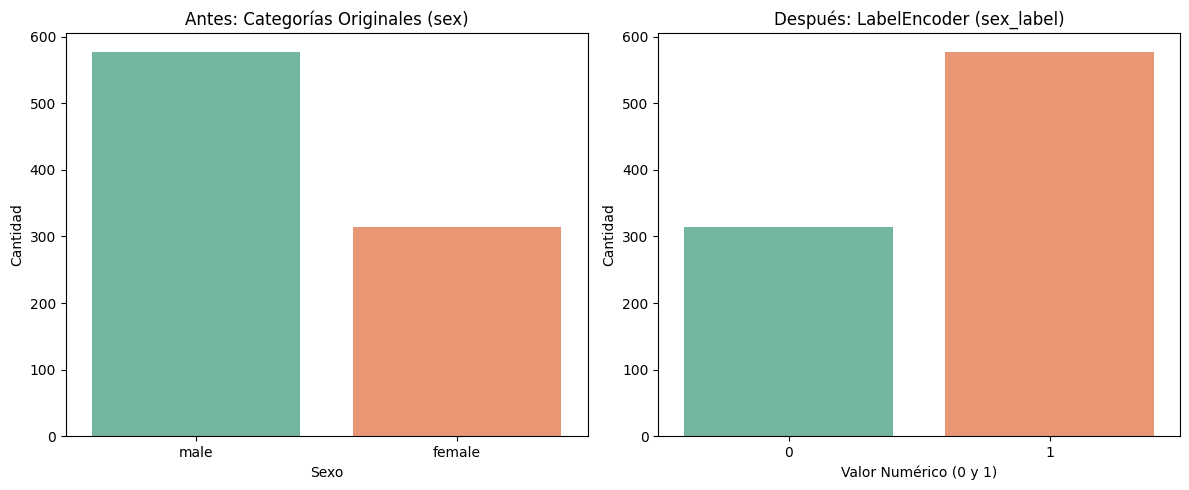

In [10]:
# Configurar la figura con dos gráficas
plt.figure(figsize=(12, 5))

# Gráfica 1: Frecuencia antes de la codificación (Texto original)
plt.subplot(1, 2, 1)
sns.countplot(data=data, x='sex', palette='Set2')
plt.title('Antes: Categorías Originales (sex)')
plt.xlabel('Sexo')
plt.ylabel('Cantidad')

# Gráfica 2: Frecuencia después de LabelEncoder (Numérico)
plt.subplot(1, 2, 2)
sns.countplot(data=data, x='sex_label', palette='Set2')
plt.title('Después: LabelEncoder (sex_label)')
plt.xlabel('Valor Numérico (0 y 1)')
plt.ylabel('Cantidad')

plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [11]:
# Aplicar OneHotEncoder a la columna 'class' del Titanic
class_onehot = pd.get_dummies(data['class'], prefix='class')

# Combinar las nuevas columnas binarias con el conjunto de datos original
data = pd.concat([data, class_onehot], axis=1)

# Visualizar la columna original y las nuevas columnas creadas
print("Comparación de la clase original con las columnas One-Hot:")
data[['class', 'class_First', 'class_Second', 'class_Third']].head()

Comparación de la clase original con las columnas One-Hot:


,class,class_First,class_Second,class_Third
0,Third,False,False,True
1,First,True,False,False
2,Third,False,False,True
3,First,True,False,False
4,Third,False,False,True


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

OneHotEncoder suele ser la opción más segura y recomendada por defecto para la gran mayoría de modelos de Machine Learning (especialmente modelos lineales, redes neuronales o basados en distancias), ya que evita que el algoritmo malinterprete los números como si fueran cantidades u orden jerárquico.